# Surface Ion Trap Optimization — Decisions and Justification
### Constrained geometry optimization for a single $^{40}\mathrm{Ca}^{+}$ ion

**Objective:** maximize the RF pseudopotential depth while meeting the ion-height, radial-frequency, Mathieu-stability and fabrication constraints.

## Result at a glance

| Saved performance | Value | Challenge requirement |
|:---|---:|:---|
| **RF-only trap depth** | **153.643 meV** | Maximize |
| Ion height above the electrodes | 59.000 µm | 50–100 µm |
| Lateral / vertical secular frequency | 6.89 / 6.97 MHz | Both ≥1 MHz |
| Mathieu parameter | 0.39911176 | ≤0.4 |
| Peak RF voltage | 100 V | ≤100 V |
| Smallest drawn feature or gap | 5 µm | ≥5 µm |

**All checks in the notebook score function pass.** These values summarize the saved outputs reproduced in Section 3 below; they are not experimental measurements.

### Selected operating point

| Parameter | Value |
|:---|---:|
| RF electrode widths | 200 µm each, symmetric |
| Gap between neighboring electrodes | 5 µm |
| Central ground electrode width | 26.71361 µm |
| Electrode thickness | 5 µm |
| Fused-silica substrate thickness | 500 µm |
| RF voltage amplitude | 100 V peak |
| RF drive frequency | 49.82812 MHz |

> **Design scope:** the starter notebook fixes the center width at 60 µm and metal thickness at 2 µm. This investigation treats those dimensions as additional design variables. The saved score passes the coded checks, which do not enforce those original fixed dimensions.

**Reading note:** historical hypotheses and failed trials are preserved as development evidence; explanations of later choices are identified separately from those original trials.

**Guide:** [1. Design development](#1-design-development) · [2. Model and implementation](#2-model-and-implementation) · [3. Results and score](#3-results-and-score) · [4. Interpretation and next steps](#4-interpretation-and-next-steps) · [5. Sources](#5-sources)

## 1. Design development

The development record below preserves the initial hypotheses, unsuccessful trials and corrections that led to the selected design. Historical parameter sets are distinguished from the executable parameters in Section 2.

### 1.1 Initial hypothesis: strengthen confinement at lower height

The RF pseudopotential is

$$\Psi(\mathbf r)=\frac{e^2|\mathbf E_{\mathrm{RF}}(\mathbf r)|^2}{4m\Omega^2},\qquad \Omega=2\pi f_{\mathrm{RF}}.$$

For a fixed geometry and voltage, lowering the drive frequency increases the pseudopotential. The initial hypothesis was that reducing ion height would also strengthen confinement; this was an exploratory assumption rather than a proof of the constrained optimum. The first Desmos plots explored the lowest allowed height and corresponding width/gap boundaries.

**Original geometry exploration — allowed height surface**

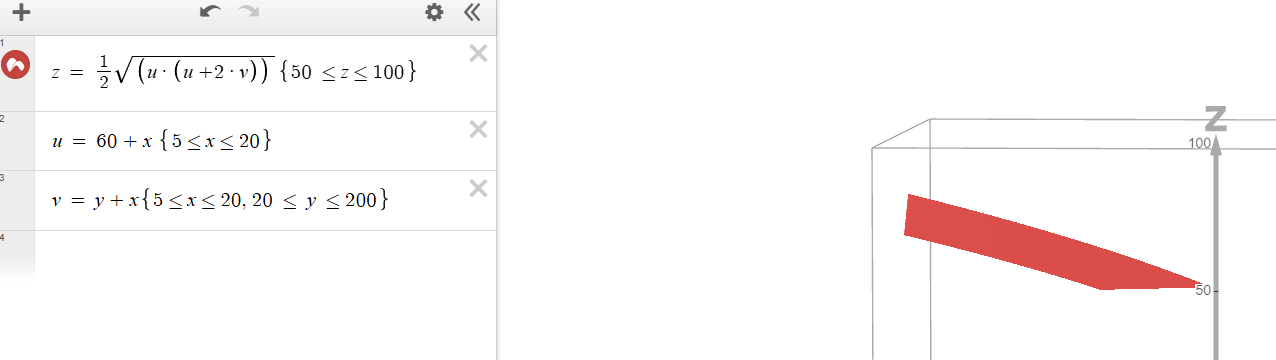

**Original boundary exploration — minimum-height candidates**

The intersection of the height boundary and the parameter limits suggested two initial test geometries.

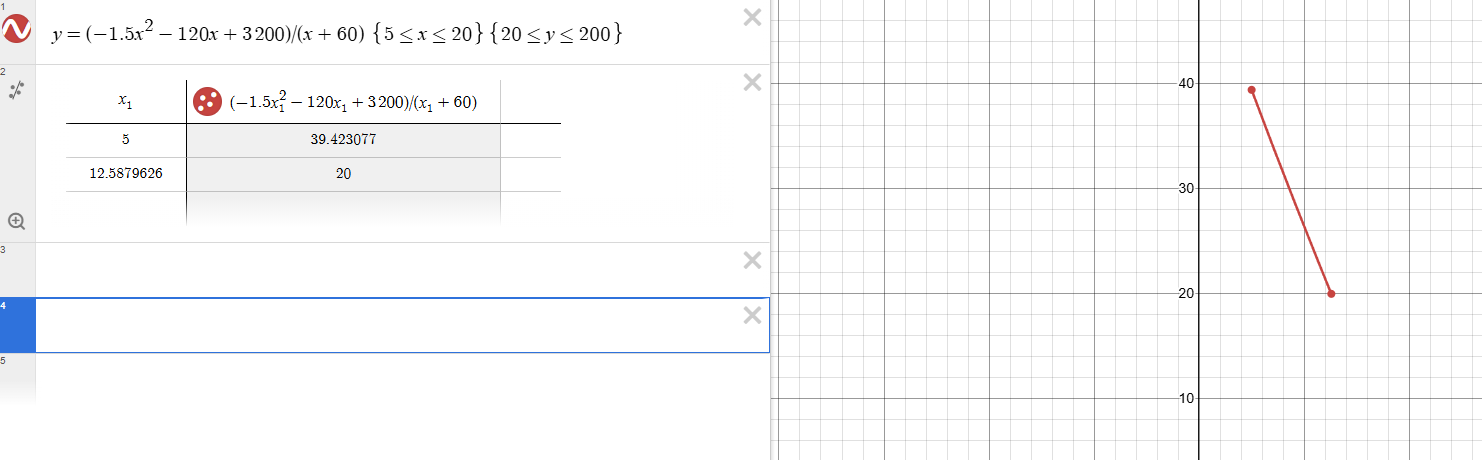

### 1.2 Failed trials identified the stability limit

| RF width (µm) | Gap (µm) | Recorded result |
|---:|---:|:---|
| 39.423007 | 5 | Failed the Mathieu constraint |
| 20 | 12.5879626 | Failed the Mathieu constraint |

The complete RF settings for both trials were not recorded alongside the geometry, so these are historical outcomes rather than fully reproducible comparison points.

The failure motivated enforcing stability while tuning frequency:

$$q_M=\frac{2\sqrt{2}\,\omega_{\mathrm{sec}}}{\Omega},\qquad
\omega_{\mathrm{sec}}=\sqrt{\frac{1}{m}\frac{\partial^2\Psi}{\partial r^2}}.$$

For a fixed geometry,

$$\Psi\propto\frac{V_{\mathrm{RF}}^2}{\Omega^2},\qquad
\omega_{\mathrm{sec}}\propto\frac{V_{\mathrm{RF}}}{\Omega},\qquad
q_M\propto\frac{V_{\mathrm{RF}}}{\Omega^2}.$$

**Conclusion:** lowering frequency alone is insufficient; it must remain high enough to satisfy $q_M\leq0.4$.

### 1.3 Literature-guided electrode ratio

Nizamani and Hensinger [1] identify a depth-maximizing RF-width/separation ratio near 3.68 for equal-width rails at fixed height and RF settings. The figure below was used during the original investigation.

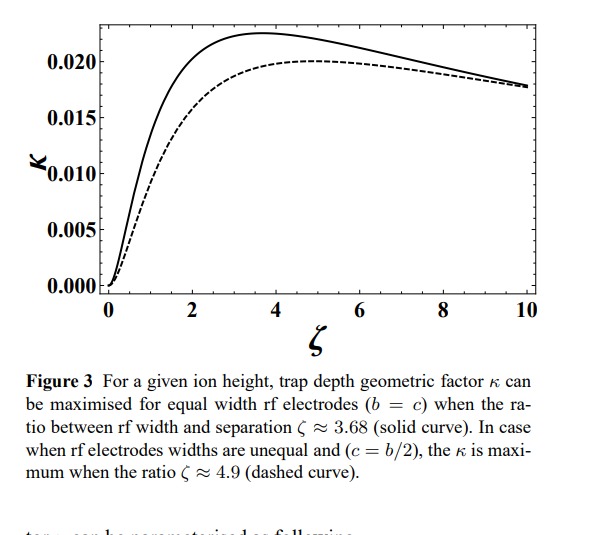

**Original Desmos comparison — applying the proposed ratio**

The ratio was initially interpreted as RF width divided by the fabrication gap. This interpretation was subsequently corrected: the denominator is the separation between the RF electrodes, including the central electrode region.

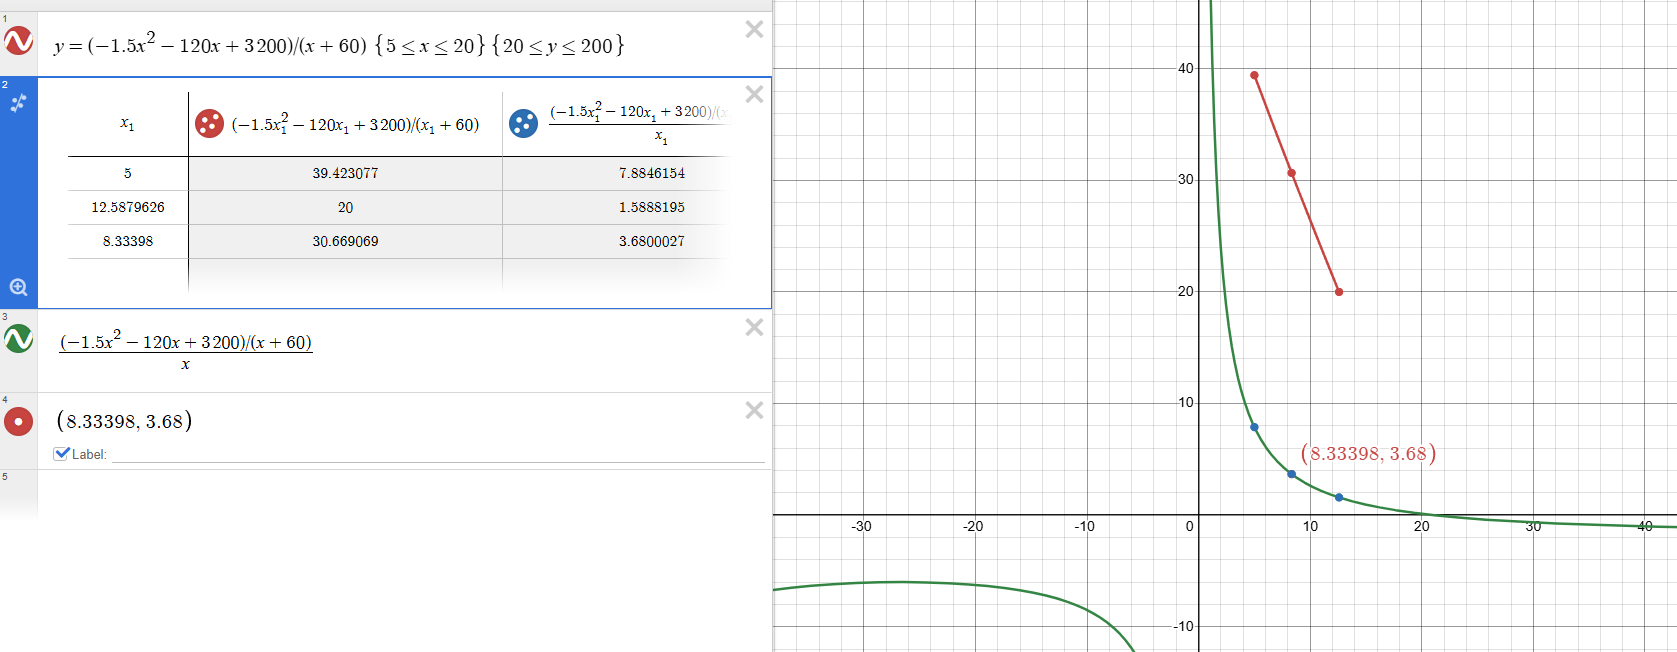

### 1.4 Balance ion height, geometry and drive frequency

The next step considered increasing ion height to reduce the field gradient and Mathieu parameter at fixed RF settings. A geometry-factor expression recorded during this stage was

$$q_M=2\sqrt{2}\frac{f_{\mathrm{sec}}}{f_{\mathrm{RF}}}
=\frac{2\epsilon eV_{\mathrm{RF}}}{m h^2(2\pi f_{\mathrm{RF}})^2},$$

where $\epsilon$ represents a geometry-dependent factor; height therefore cannot be optimized independently of electrode geometry.

The early Desmos exploration reported a height boundary near 73.10266 µm while the original ratio interpretation was still being investigated.

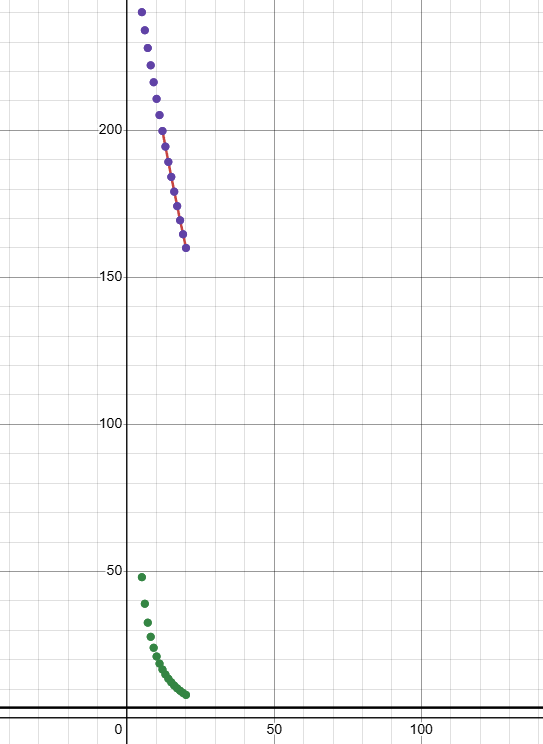

#### Historical parameter milestones

| Stage | RF width (µm) | Gap (µm) | Center (µm) | Peak RF (V) | Drive (MHz) | Interpretation |
|:---|---:|---:|---:|---:|---:|:---|
| Intermediate trial | 73.6 | 20 | 60 | 100 | 40.875 | Based on the early ratio interpretation |
| Corrected separation | 200 | 5 | 44.348 | 100 | 40.6 | Recorded score ≈150.4 meV |
| Frequency refinement | 200 | 5 | 44.348 | 100 | 40.5823859 | Historical refinement near the Mathieu limit |
| Current notebook | 200 | 5 | 26.71361 | 100 | 49.4 | Saved result: 151.622 meV |

The original tuning notes also recorded $V/f^2=64/(32.7\times10^6)^2$ near a Mathieu-limited operating point. This is a historical scaling reference, not an additional current simulation result. The corrected-separation trial recorded approximately 1.5041 meV per volt; the current saved score records approximately 1.5162 meV per volt.

#### Why the selected effective ratio is about 6.46

Using the starter's gap-sharing approximation,

$$a_{\mathrm{eff}}=w_{\mathrm{center}}+g,\qquad
b_{\mathrm{eff}}=w_{\mathrm{RF}}+g,$$

$$\frac{b_{\mathrm{eff}}}{a_{\mathrm{eff}}}
=\frac{200+5}{26.71361+5}\approx6.46.$$

This does not contradict the published 3.68 value: the later search allows frequency and height to vary while enforcing the Mathieu bound, so it optimizes a different objective. The ideal-model ratio is not a proven global optimum for finite-thickness electrodes.

## 2. Model and implementation

### 2.1 Dependencies


In [1]:
import matplotlib.pyplot as plt
import numpy as np
import photonforge as pf
import tidy3d as td
from scipy.constants import atomic_mass, elementary_charge
from scipy.integrate import cumulative_trapezoid

# We raise the Tidy3D logging level to reduce output noise from the solve
# below. Warnings can flag real problems, so only suppress them once you have
# confirmed they are not relevant to your case.
td.config.logging.level = "ERROR"


### 2.2 Active design parameters

The cell below defines the operating point used by the saved results. Widths, gaps and thicknesses are in **µm**, voltage is the **peak RF amplitude**, and frequency is in **Hz**. Both RF rails have the same width and phase.

#### Why these values were selected

| Decision | Justification and evidence | Qualification |
|:---|:---|:---|
| Equal RF rails | Independent-width analytic screening returned approximately equal widths, supporting symmetry for the depth objective. | Unequal rails may still be useful for optical access or mode orientation; those are different objectives. |
| RF width = 200 µm | The constrained analytic search favored the upper allowed rail width for the fixed-center comparison; the final geometry retains that width. | The final finite-thickness geometry was not jointly optimized over every parameter. |
| Gap = 5 µm | Select the smallest permitted gap as a screened candidate while limiting exposed dielectric and retaining the fabrication constraint. | Finished gaps must remain at least 5 µm after plating; a smaller gap does not guarantee greater depth in every geometry. |
| Center = 26.71361 µm | Relaxing the fixed-center rule allowed an analytic geometry with a larger depth-to-stability benefit; the value is one representative of an ideal-model optimum family. | It changes the starter's fixed 60 µm center and is not a unique physical optimum. |
| RF amplitude = 100 V peak | At fixed frequency, depth scales as voltage squared; after retuning to a fixed Mathieu bound, depth increases approximately linearly with voltage. | The voltage must be sustainable at the electrode, with the stability bound and practical breakdown limit enforced. |
| Drive = 49.4 MHz | This is the operating point stored in the current notebook, whose saved output gives $q_M=0.39911176$ and passes the score. | It is not the 50.141 MHz operating point of the separate fixed-window thickness screen. |
| Metal = 5 µm | Several-micrometre plated gold is supported by fabrication literature, and 5 µm led the six-case thickness screen. | The small predicted advantage over 10 µm is not established beyond mesh uncertainty. |

These explanations combine the recorded development history with the later analysis; they do not imply that every final value was established by the original early trials.


In [2]:
# Width of each RF electrode, allowed range 20 to 200 (μm)
rf_width = 200

# Gap between neighbouring electrodes, allowed range 5 to 20 (μm)
gap = 5

# Peak RF voltage on the RF electrodes, allowed range 10 to 100 (V)
v_rf = 100

# RF drive frequency, allowed range 10e6 to 60e6 (Hz)
f_rf = 49.82812e6

# Width of the central ground electrode
center_width = 26.71361

# Thickness of the electrodes (μm)
metal_thickness = 5.0  

### 2.3 Material constants and analytic height estimate

The gapless estimate provides a geometry check before the finite-gap solve:

$$h_{\mathrm{estimate}}=\frac12\sqrt{a_{\mathrm{eff}}(a_{\mathrm{eff}}+2b_{\mathrm{eff}})}.$$

The estimate and the sampled finite-gap height need not agree exactly.

**Decision:** retain the 500 µm fused-silica wafer and use the analytic height as a screening check. **Reason:** the separate 300/500 µm comparison showed negligible depth benefit from thinning, while retaining the original substrate avoids an unnecessary fabrication change. The height estimate is evaluated before a cloud solve because it can reject unsuitable geometry cheaply; it is not substituted for the finite-gap result.


In [3]:


substrate_thickness = 500.0  # Thickness of the fused-silica substrate (μm)
silica_permittivity = 3.8  # Relative permittivity of fused silica

ion_mass = 40 * atomic_mass  # Mass of a 40Ca+ ion (kg)
ion_charge = elementary_charge  # Charge of a 40Ca+ ion (C)

# Effective electrode widths of the gapless model (μm)
a_eff = center_width + gap
b_eff = rf_width + gap

# Ion height from the closed-form gapless model (μm)
h_estimate = 0.5 * np.sqrt(a_eff * (a_eff + 2 * b_eff))
print(f"Estimated ion height: {h_estimate:.3f} μm")


Estimated ion height: 59.178 μm


### 2.4 Cross-section, technology and mesh

The model is translationally invariant along the trap axis. Gold electrodes are represented as perfect electric conductors (PEC), so the calculation captures the field geometry but does not predict material resistance or RF heating. Mirror symmetry is valid because both RF rails are identical and driven in phase.



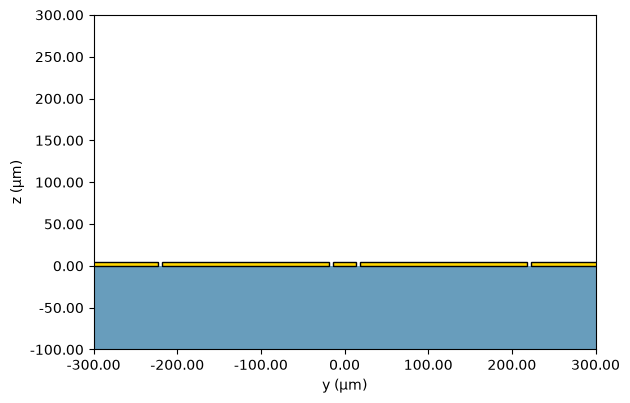

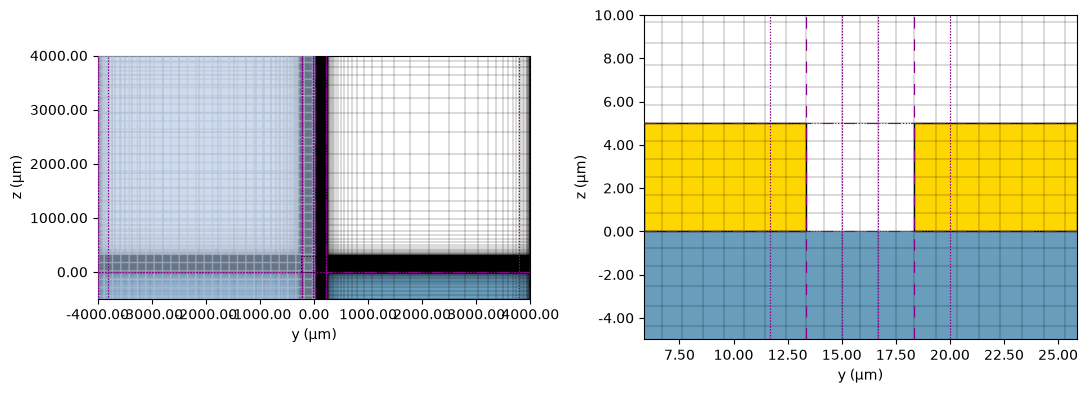

In [4]:
# Fused-silica substrate and perfectly conducting electrodes
silica = td.Medium(permittivity=silica_permittivity, name="Fused silica")

# One layout layer for the electrode metal
layers = {"METAL": pf.LayerSpec((1, 0), "Trap electrodes", "#b8a18b18", "\\")}

# Extrude the substrate under the whole chip, then the electrodes on top of it
extrusion_specs = [
    pf.ExtrusionSpec(pf.MaskSpec(), silica, (-substrate_thickness, 0)),
    pf.ExtrusionSpec(pf.MaskSpec((1, 0)), td.PEC, (0, metal_thickness)),
]

# Assemble the technology with an air background and make it the default
technology = pf.Technology(
    "Surface trap", "1.0", layers, extrusion_specs, {}, td.Medium()
)
pf.config.default_technology = technology


# Centre of each RF rail and inner edge of each outer ground along y (μm)
y_rf = center_width / 2 + gap + rf_width / 2
y_outer = center_width / 2 + 2 * gap + rf_width

# Half-width of the solver window and its height above the chip (μm)
half_width = 4000
top_height = 4000

# Width of each outer ground, reaching past the window edge (μm)
outer_width = half_width - y_outer + 100

# Cross-section of the five-wire trap
trap_spec = pf.PortSpec(
    description="Five-wire trap",
    width=2 * half_width,
    limits=(-substrate_thickness, top_height),
    num_modes=2,
    target_neff=1.5,
    path_profiles={
        "center": (center_width, 0, "METAL"),
        "rf0": (rf_width, y_rf, "METAL"),
        "rf1": (rf_width, -y_rf, "METAL"),
        "ground0": (outer_width, y_outer + outer_width / 2, "METAL"),
        "ground1": (outer_width, -y_outer - outer_width / 2, "METAL"),
    },
    voltage_path=[(y_outer, metal_thickness / 2), (y_rf, metal_thickness / 2)],
)

# Plot the cross-section around the trap
ax = pf.tidy3d_plot(trap_spec, frequency=f_rf)
ax.set_xlim(-300, 300)
ax.set_ylim(-100, 300)
ax.set_title("")
plt.show()


# Mode solver for the cross-section at the drive frequency
trap_solver = trap_spec.to_tidy3d([f_rf])

# Mesh the region of the ion and its escape point with 1 μm cells
ion_region = td.MeshOverrideStructure(
    geometry=td.Box.from_bounds((-1, -y_outer - 20, -10), (1, y_outer + 20, 300)),
    dl=(None, 1.0, 1.0),
)
grid_spec = trap_solver.simulation.grid_spec.updated_copy(
    override_structures=[ion_region]
)

# Solve only the half y > 0, using the mirror symmetry of the trap
simulation = trap_solver.simulation.updated_copy(
    symmetry=(0, 1, 0), grid_spec=grid_spec
)
trap_solver = trap_solver.updated_copy(simulation=simulation)

fig, ax = plt.subplots(1, 2, figsize=(11, 4), tight_layout=True)

# Whole solver window with its mesh
simulation.plot(x=0, ax=ax[0])
simulation.plot_grid(x=0, ax=ax[0])

# Close-up of the gap between the central ground and an RF rail
y_gap = center_width / 2 + gap / 2
simulation.plot(
    x=0, ax=ax[1], hlim=(y_gap - 2 * gap, y_gap + 2 * gap), vlim=(-gap, 2 * gap)
)
simulation.plot_grid(
    x=0, ax=ax[1], hlim=(y_gap - 2 * gap, y_gap + 2 * gap), vlim=(-gap, 2 * gap)
)
for a in ax:
    a.set_title("")
plt.show()

### 2.5 Cloud mode solve

The solver returns two quasi-TEM modes used to reconstruct the field of the desired electrode voltages.

> **Execution note:** this cell submits a PhotonForge cloud solve and may consume simulation credits when no cached result exists. Existing outputs can be reviewed without rerunning it.

**Justification:** obtain field basis functions for the actual finite-gap cross-section instead of relying only on the analytic gapless approximation. Two modes are retained for the symmetric half-cross-section so that the RF-rail voltage and central-ground condition can be imposed independently during reconstruction. Reusing a field solution for voltage-only scaling avoids unnecessary geometry solves.


In [5]:
# Solve for the two quasi-TEM modes of the electrode cross-section
trap_solver = pf.port_modes(trap_solver, task_name="Surface trap")

# Effective index of each mode
print("Effective indices:", trap_solver.data.n_eff.values.ravel())

Uploading task 'Surface trap…'
Starting task 'Surface trap': https://tidy3d.simulation.cloud/workbench?taskId=mo-aaf47cfd-6bae-4895-8ab9-8537277cc3d9
Progress: 100% 
Effective indices: [1.46103129 1.39162159]


### 2.6 Mode-field visualization

The two mode fields are basis solutions. Neither alone is the final trap field; their weighted combination enforces the RF and ground electrode voltages.

**Reason for this check:** Honestly I just wanted to see the really cool graphs



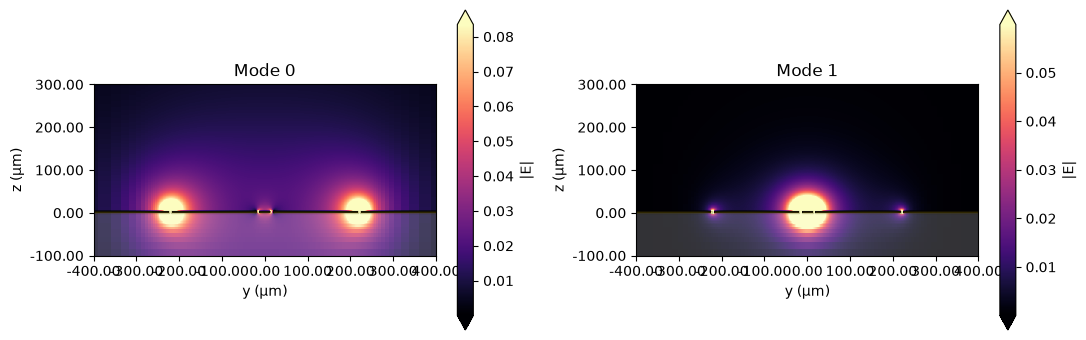

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5), tight_layout=True)

# Electric field magnitude of each mode around the trap
for m in range(2):
    trap_solver.plot_field("E", "abs", mode_index=m, f=f_rf, ax=ax[m])
    ax[m].set_xlim(-400, 400)
    ax[m].set_ylim(-100, 300)
    ax[m].set_title(f"Mode {m}")
plt.show()

## 3. Results and score

### 3.1 Reconstruct the RF field and calculate confinement

This is all from the score calculation given in the orginial starting notebook.




In [7]:
# Mode fields on the cross-section at the drive frequency
fields = {
    component: trap_solver.data.field_components[component].isel(f=0).squeeze(drop=True)
    for component in ("Ey", "Ez")
}

# Line at mid-height of the electrodes, from inside the outer ground to the centre (μm)
y_line = np.linspace(y_outer + gap / 2, 0, 4001)

# Potential along the line in each mode, relative to the outer ground (V)
potentials = [
    -cumulative_trapezoid(
        fields["Ey"].isel(mode_index=m).interp(y=y_line, z=metal_thickness / 2).values,
        y_line,
        initial=0,
    )
    for m in range(2)
]

# Voltage of the RF rail (first row) and of the central ground (second row) in each mode
voltages = np.array(
    [
        [np.interp(y_rf, y_line[::-1], phi[::-1]) for phi in potentials],
        [phi[-1] for phi in potentials],
    ]
)

# Mode weights that put the RF rail at 1 V and the central ground at 0 V
weights = np.linalg.solve(voltages, [1.0, 0.0])

# Field of the trap per volt on the RF rails (V/μm)
e_unit = {
    component: sum(weights[m] * fields[component].isel(mode_index=m) for m in range(2))
    for component in fields
}
# Regular sampling grid around the trap (μm)
y_grid = np.arange(-150, 150.01, 0.5)
z_grid = np.arange(metal_thickness + 1, 350, 0.5)

# Squared field magnitude per volt on the grid, shape (y, z), in (V/μm)²
e2_unit = sum(
    np.abs(e_unit[component].interp(y=y_grid, z=z_grid).values) ** 2
    for component in e_unit
)

# Pseudopotential in J; the factor 1e12 converts (V/μm)² to (V/m)²
omega_rf = 2 * np.pi * f_rf
psi = ion_charge**2 * v_rf**2 * e2_unit * 1e12 / (4 * ion_mass * omega_rf**2)

# Pseudopotential in meV
psi_mev = psi / elementary_charge * 1e3

# Pseudopotential along the symmetry axis y = 0
i_axis = np.argmin(np.abs(y_grid))
psi_axis = psi[i_axis, :]

# Ion position: minimum of the pseudopotential on the axis
i_ion = np.argmin(psi_axis)
z_ion = z_grid[i_ion]
ion_height = z_ion - metal_thickness

# Escape point: maximum of the pseudopotential above the ion
i_saddle = i_ion + np.argmax(psi_axis[i_ion:])
trap_depth = psi_mev[i_axis, i_saddle] - psi_mev[i_axis, i_ion]

# Points within 3 μm of the ion for the parabola fits
fit_range = 3.0
near_z = np.abs(z_grid - z_ion) <= fit_range
near_y = np.abs(y_grid) <= fit_range

# Curvature of the pseudopotential along z and y (J/μm²)
curvature_z = 2 * np.polyfit(z_grid[near_z] - z_ion, psi_axis[near_z], 2)[0]
curvature_y = 2 * np.polyfit(y_grid[near_y], psi[near_y, i_ion], 2)[0]

# Secular angular frequencies; the factor 1e12 converts 1/μm² to 1/m²
omega_z = np.sqrt(curvature_z * 1e12 / ion_mass)
omega_y = np.sqrt(curvature_y * 1e12 / ion_mass)

# Radial secular frequency (Hz) and Mathieu parameter
f_secular = min(omega_y, omega_z) / (2 * np.pi)
q_mathieu = 2 * np.sqrt(2) * max(omega_y, omega_z) / omega_rf

print(f"Ion height above the electrodes: {ion_height:.3f} μm")
print(f"Secular frequency, lateral: {omega_y / 2 / np.pi / 1e6:.2f} MHz")
print(f"Secular frequency, vertical: {omega_z / 2 / np.pi / 1e6:.2f} MHz")
print(f"Mathieu parameter q: {q_mathieu:.8f}")
print(f"Trap depth: {trap_depth:.3f} meV")


Ion height above the electrodes: 58.000 μm
Secular frequency, lateral: 6.99 MHz
Secular frequency, vertical: 7.05 MHz
Mathieu parameter q: 0.39999986
Trap depth: 153.643 meV


### 3.2 Pseudopotential landscape

The dark minimum marks the RF null and the cyan escape marker identifies the sampled barrier above it. The plotted depth is the **RF-only radial escape barrier** of this cross-section, not a fully qualified three-dimensional trapping depth with axial DC confinement.

**Reason for this figure:** Honestly I just wanted to see this cool graph aswell, it was interesting to see how the parameters changed the surrounding shape of the chart.


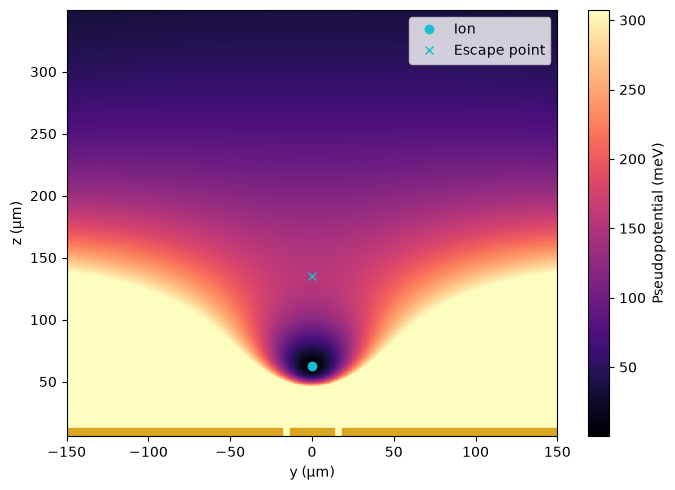

In [8]:
fig, ax = plt.subplots(figsize=(7, 5), tight_layout=True)

# Pseudopotential map in meV
mesh = ax.pcolormesh(
    y_grid, z_grid, psi_mev.T, vmax=2 * trap_depth, cmap="magma", shading="auto"
)
fig.colorbar(mesh, ax=ax, label="Pseudopotential (meV)")

# Ion position and escape point
ax.plot(0, z_ion, "o", color="tab:cyan", label="Ion")
ax.plot(0, z_grid[i_saddle], "x", color="tab:cyan", label="Escape point")

# Electrode positions along the bottom edge
for y0, y1 in [
    (-center_width / 2, center_width / 2),
    (center_width / 2 + gap, center_width / 2 + gap + rf_width),
    (-center_width / 2 - gap - rf_width, -center_width / 2 - gap),
]:
    ax.axvspan(y0, y1, ymax=0.02, color="goldenrod")
ax.set_xlabel("y (μm)")
ax.set_ylabel("z (μm)")
ax.set_xlim(y_grid[0], y_grid[-1])
ax.legend(loc="upper right")
plt.show()

### 3.3 Constraint checks and score

The original score function returns depth only when all coded checks pass. The printed score is rounded to one decimal place; the saved confinement output above reports **153.642 meV**.

The voltage-normalized diagnostic is retained, but the challenge objective is depth rather than meV per volt. The function does not enforce the starter's original fixed center width or metal thickness.

**Decision rule:** prefer a feasible design over a deeper but unstable candidate. The pass/fail checks therefore precede accepting the depth as a score. Listing the fixed-dimension scope exception separately makes clear why passing the numerical function is not equivalent to meeting every unmodified starter specification.


In [9]:
def trap_score(ion_height, f_secular, q_mathieu, v_rf, min_feature, trap_depth):
    # Pass or fail for every constraint of the challenge
    checks = {
        "Ion height 50 to 100 μm": 50 <= ion_height <= 100,
        "Radial secular frequency at least 1 MHz": f_secular >= 1e6,
        "Mathieu parameter q at most 0.4": q_mathieu <= 0.4,
        "Peak RF voltage at most 100 V": v_rf <= 100,
        "Minimum electrode feature or gap at least 5 μm": min_feature >= 5,
    }

    # Print the outcome of each check
    for name, passed in checks.items():
        print(f"{'PASS' if passed else 'FAIL'}  {name}")

    # Trap depth if every constraint passes, zero otherwise
    return trap_depth if all(checks.values()) else 0.0


# Smallest drawn feature or gap of the layout (μm)
min_feature = min(center_width, rf_width, gap)

# Score of the current design
score = trap_score(ion_height, f_secular, q_mathieu, v_rf, min_feature, trap_depth)
print(f"\nScore: {score:.1f} meV at {v_rf:.0f} V")
print("meV per voltage: " + str(score/v_rf ))

PASS  Ion height 50 to 100 μm
PASS  Radial secular frequency at least 1 MHz
PASS  Mathieu parameter q at most 0.4
PASS  Peak RF voltage at most 100 V
PASS  Minimum electrode feature or gap at least 5 μm

Score: 153.6 meV at 100 V
meV per voltage: 1.5364306259475873


## 4. Interpretation and next steps

### Findings

- **Stability controls frequency selection:** lowering the drive increases both depth and Mathieu parameter, so the search must enforce the stability bound throughout.
- **Symmetric rails remain the selected layout:** the separate analytic search with independent rail widths converged to approximately equal widths; this is model evidence rather than a complete finite-gap asymmetry study.


### Remaining validation

1. Confirm mesh/domain convergence and solve at the final selected RF frequency.
2. Include axial DC confinement and search the complete escape barrier.
3. Check the final fabricated gap, electrode tolerances, adhesion and breakdown behavior.
4. For a material change, measure film resistance and model the RF feed, resonator, phase balance and thermal behavior.

The current values are numerical results, not experimental device measurements. No cloud solves were submitted during this presentation-only notebook cleanup.

## 5. Sources

[1] A. H. Nizamani and W. K. Hensinger, “Optimum electrode configurations for fast ion separation in microfabricated surface ion traps,” *Appl. Phys. B*, vol. 106, no. 2, pp. 327–338, 2012, doi: [10.1007/s00340-011-4803-x](https://doi.org/10.1007/s00340-011-4803-x). **Contribution:** electrode-width/separation ratio and asymmetric geometry context.

[2] D. T. C. Allcock et al., “Implementation of a symmetric surface electrode ion trap with field compensation using a modulated Raman effect,” *New J. Phys.*, vol. 12, Art. no. 053026, 2010, doi: [10.1088/1367-2630/12/5/053026](https://arxiv.org/abs/0909.3272). **Contribution:** symmetric layouts with DC-controlled mode rotation.

[3] J. Tao et al., “Functional surface ion traps on a 12-inch glass wafer for quantum applications,” arXiv:2002.11470, 2020. [Online](https://arxiv.org/pdf/2002.11470). **Contribution:** working Cu/Au electrodes on a glass substrate; fabrication precedent rather than a measured improvement for this design.

[4] R. Schmied, “Electrostatics of gapped and finite surface electrodes,” *New J. Phys.*, vol. 12, Art. no. 023038, 2010, doi: [10.1088/1367-2630/12/2/023038](https://doi.org/10.1088/1367-2630/12/2/023038). **Contribution:** finite-electrode and dielectric corrections beyond the ideal gapless model.

**Project basis:** [starter notebook](starter_file_given.ipynb). Additional fabrication, resistance, skin-effect and surface-physics references are collected in the [IEEE bibliography](IEEE_BIBLIOGRAPHY.md).